# Projeto Final PSI3472 — Planejamento de Voos Nacionais com Algoritmo Genético

**Fluxo de avaliação de um indivíduo**

```
GENOMA ──decodificar──► TAB_AV (voos + aeronaves) ──alocar──► TAB_AP (passageiros) ──► FITNESS
  ▲                                                                                        │
  └──────────────── seleção / cruzamento / mutação atuam só sobre o genoma ◄───────────────┘
```

**Organização do notebook**

| Seção | Conteúdo |
|---|---|
| 0 | Dados do enunciado (TAB_TV, TAB_OD) e parâmetros |
| 1 | Genoma: estrutura, decodificador, geração aleatória e tabelas (TAB_AV, TAB_PV, TAB_MV) |
| 2 | Alocação de passageiros (TAB_AP), `cria_tabelas` e `mostra_tabela` |
| 3 | Função de avaliação (fitness) e `score` |
| 4 | Algoritmo genético: seleção, cruzamento, mutação e laço principal |
| 5 | Resultados: o melhor plano encontrado |

In [1]:
import random
import time
from dataclasses import dataclass, field

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

---
## 0. Dados e parâmetros

Parâmetros do enunciado e as hipóteses adotadas pelo grupo onde o enunciado é omisso.

In [2]:
# ---- Parâmetros do enunciado ----
N_AERONAVES        = 400   # frota disponível
CAPACIDADE         = 200   # passageiros por aeronave
PRIMEIRA_DECOLAGEM = 6     # 06:00
ULTIMA_DECOLAGEM   = 21    # 21:00 — última decolagem permitida (chegadas podem ser depois)
ESCALA_MIN_H       = 1     # escala mínima do passageiro: 60 min (usada na Seção 2)

# ---- Parâmetro do alocador (Seção 2) ----
MAX_ESCALAS = 2            # "escala": nº máximo de escalas por passageiro; acima disso, remanescente

# ---- Hipóteses do grupo (não especificadas no enunciado) ----
TURNAROUND_H = 1           # tempo mínimo da aeronave em solo entre pousar e decolar de novo

# ---- Geração aleatória de genes (Seção 1.4) ----
# Não limita o que é possível (não há nº máximo de voos nem espera máxima): só define como o acaso
# propõe genes. Quem decide o que é viável é a validação; quem decide o que é bom é a seleção.
P_ESPERA = 0.5             # espera ~ geométrica: 0 h (50%), 1 h (25%), 2 h (12,5%)... sem limite

### 0.1 Aeroportos e TAB_TV — tempos de voo (min)
Linha = origem, coluna = destino. A diagonal é 0 (não há voo de um aeroporto para ele mesmo).
Os totais de linha/coluna são conferidos contra os do PDF para evitar erro de digitação.

In [3]:
AEROPORTOS = ["MA", "BE", "FO", "NA", "RE", "SA", "BR", "BH", "CI", "RJ", "SP", "CR", "FL", "PA"]
NOMES = {
    "MA": "Manaus", "BE": "Belém", "FO": "Fortaleza", "NA": "Natal", "RE": "Recife",
    "SA": "Salvador", "BR": "Brasília", "BH": "Belo Horizonte", "CI": "Cuiabá",
    "RJ": "Rio de Janeiro", "SP": "São Paulo", "CR": "Curitiba", "FL": "Florianópolis",
    "PA": "Porto Alegre",
}

_TV = [
#     MA   BE   FO   NA   RE   SA   BR   BH   CI   RJ   SP   CR   FL   PA
    [  0, 120, 180, 180, 180, 180, 180, 240, 180, 300, 300, 300, 360, 360],  # MA
    [120,   0, 120, 120, 120, 180, 180, 240, 180, 240, 240, 300, 300, 360],  # BE
    [180, 120,   0,  60,  60, 120, 180, 180, 240, 240, 240, 300, 300, 360],  # FO
    [180, 120,  60,   0,  60, 120, 180, 180, 240, 240, 240, 300, 300, 360],  # NA
    [180, 120,  60,  60,   0, 120, 180, 180, 240, 180, 180, 240, 240, 300],  # RE
    [180, 180, 120, 120, 120,   0, 120, 120, 180, 120, 120, 180, 180, 240],  # SA
    [180, 180, 180, 180, 180, 120,   0,  60,  60, 120, 120, 180, 180, 240],  # BR
    [240, 240, 180, 180, 180, 120,  60,   0, 120,  60,  60, 120, 120, 180],  # BH
    [180, 180, 240, 240, 240, 180,  60, 120,   0, 180, 180, 180, 180, 240],  # CI
    [300, 240, 240, 240, 180, 120, 120,  60, 180,   0,  60, 120, 120, 180],  # RJ
    [300, 240, 240, 240, 180, 120, 120,  60, 180,  60,   0,  60,  60, 120],  # SP
    [300, 300, 300, 300, 240, 180, 180, 120, 180, 120,  60,   0,  60,  60],  # CR
    [360, 300, 300, 300, 240, 180, 180, 120, 180, 120,  60,  60,   0,  60],  # FL
    [360, 360, 360, 360, 300, 240, 240, 180, 240, 180, 120,  60,  60,   0],  # PA
]
TAB_TV = pd.DataFrame(_TV, index=AEROPORTOS, columns=AEROPORTOS)

# Conferência com os totais do PDF
_TOTAIS_TV = [3060, 2700, 2580, 2580, 2280, 1980, 1980, 1860, 2400, 2160, 1980, 2400, 2460, 3060]
assert TAB_TV.sum(axis=1).tolist() == _TOTAIS_TV
assert TAB_TV.sum(axis=0).tolist() == _TOTAIS_TV
# Obs.: o PDF mostra total geral 34480, mas a soma dos próprios totais de linha dá 33480 (erro no PDF).
assert TAB_TV.values.sum() == 33480
assert (TAB_TV.values % 60 == 0).all(), "todos os tempos devem ser múltiplos de 60 min"

# Acesso rápido em HORAS: TV_H[origem][destino]
TV_H = {o: {d: int(TAB_TV.at[o, d]) // 60 for d in AEROPORTOS if d != o} for o in AEROPORTOS}

### 0.2 TAB_OD — demanda diária de passageiros (origem → destino)
Cada passageiro é contado uma vez pela viagem completa (com ou sem escala).

In [4]:
_OD = [
#      MA    BE    FO    NA    RE    SA    BR    BH    CI    RJ    SP    CR    FL    PA
    [   0,  800,  900,  600,  900,  900, 1600,  800,  500, 1700, 2200,  800,  400,  600],  # MA
    [ 900,    0, 1100,  800,  700, 1100, 1400,  900,  300, 1800, 1800,  800,  400,  500],  # BE
    [ 600,  900,    0, 1200, 1200, 1200, 1700, 1000,  400, 2300, 1600,  900,  600,  800],  # FO
    [ 400,  700, 1000,    0,  900, 1200, 1400,  600,  600, 1400, 1600,  900,  600,  700],  # NA
    [ 600,  800, 1500, 1100,    0, 1400, 1900,  700,  900, 2600, 2400, 1100,  900,  900],  # RE
    [ 400,  500, 1600, 1500, 1400,    0, 2100, 1100, 1100, 2400, 2500, 1100, 1100, 1100],  # SA
    [ 900, 1100, 1800, 1400, 1700, 2100,    0, 1500, 1700, 3600, 7800, 1300, 1200, 1400],  # BR
    [ 400,  900, 1100,  600, 1200,  800, 2200,    0,  800, 1400, 1800,  700,  500,  600],  # BH
    [ 500,  500,  900,  800,  900,  600, 1000,  700,    0, 1000, 1400,  500,  400,  500],  # CI
    [1200,  900, 2000, 1500, 2100, 2400, 3700, 1900, 1800,    0, 8100, 1700, 1500, 1700],  # RJ
    [1500, 1600, 3000, 1800, 3100, 2600, 5900,  600, 1700, 7000,    0, 3000, 2100, 2200],  # SP
    [ 300,  800, 1000,  700,  800, 1200, 1400,  900,  600, 1600, 1600,    0,  700, 1100],  # CR
    [ 300,  700,  900, 1400,  900, 1300, 1600, 1100,  600, 2000, 1800, 1000,    0,  700],  # FL
    [ 300,  600,  800, 1100,  500, 1100, 1500,  900,  400, 1900, 1500,  700,  600,    0],  # PA
]
TAB_OD = pd.DataFrame(_OD, index=AEROPORTOS, columns=AEROPORTOS)

# Conferência com os totais do PDF
assert TAB_OD.sum(axis=1).tolist() == [12700, 12500, 14400, 12000, 16800, 17900, 27500,
                                       13000, 9700, 30500, 36100, 12700, 14300, 11900]
assert TAB_OD.sum(axis=0).tolist() == [8300, 10800, 17600, 14500, 16300, 17900, 27400,
                                       12700, 11400, 30700, 36100, 14500, 11000, 12800]
assert TAB_OD.values.sum() == 242_000

# Acesso rápido: DEMANDA[(origem, destino)]
TRECHOS = [(o, d) for o in AEROPORTOS for d in AEROPORTOS if o != d]   # 182 pares O-D
DEMANDA = {(o, d): int(TAB_OD.at[o, d]) for o, d in TRECHOS}

---
## 1. Genoma — estrutura, validação, decodificação e tabelas

### Estrutura do genoma

```
genoma = [ gene_A001, gene_A002, ..., gene_A400 ]          (um gene por aeronave)

gene   = base | (destino₁, espera₁) | (destino₂, espera₂) | ... | (destinoₙ, esperaₙ)
```

- **base**: aeroporto onde a aeronave amanhece (primeiro voo parte daí, a partir das 06:00).
- **destino**: próximo aeroporto. A lista acaba quando a aeronave encerra o dia (n = 0 é um avião parado).
- **espera**: horas extras em solo antes de decolar, além do turnaround.

**Como num genoma real, não há restrição de combinação.** O gene pode ter qualquer tamanho e qualquer
espera, e qualquer aeroporto pode aparecer em qualquer posição. Não existe nº máximo de voos nem espera
máxima. O que separa um genoma possível de um impossível é a **validação** (`verificar_gene` /
`validar_genoma`, Seção 1.4), que aplica as leis da física:

1. não existe voo para o próprio aeroporto (destino ≠ onde a aeronave está);
2. toda decolagem acontece até as 21:00;
3. a espera não é negativa.

Genoma inválido é **descartado** e outro é gerado no lugar ("embrião inviável"). Entre os válidos, quem
decide o que sobrevive é a seleção natural do AG (fitness). O limite de voos por dia aparece
sozinho: com o menor voo (1 h) e o turnaround (1 h), cabem no máximo 8 decolagens entre 06h e 21h.

**Decisões de projeto**

- A **origem** de cada voo não está no genoma: é sempre o destino do voo anterior ⇒ é impossível uma aeronave "se teletransportar".
- Os **horários** também não estão no genoma: são calculados pelo decodificador
  (`partida = disponível + espera`, `chegada = partida + TV`, `disponível = chegada + turnaround`) ⇒ nunca ficam inconsistentes.
- **Passageiros não estão no genoma**: o nº de passageiros de cada voo é consequência da demanda e é calculado pelo alocador (Seção 2).

### 1.1 O gene da aeronave

In [5]:
@dataclass
class GeneAeronave:
    """Gene de uma aeronave: onde ela amanhece e a sequência de (destino, espera), de qualquer tamanho."""
    base: str
    trechos: list   # list[tuple[str, int]]

    def __str__(self):
        return " | ".join([self.base] + [f"{d}+{e}" for d, e in self.trechos]) + " | fim"

### 1.2 Fenótipo: `Voo`, `Aeronave` e `Plano`

O fenótipo é o que o genoma "produz". Cada indivíduo tem o seu próprio `Plano`.
`Voo.ocupacao` fica vazio aqui e será preenchido pelo alocador na Seção 2, no formato
`{(origem_final, destino_final): n_passageiros}`.

In [6]:
def fmt_hora(h):
    """Formata hora inteira; chegadas após meia-noite aparecem como (+1d)."""
    return f"{h:02d}:00" if h < 24 else f"{h - 24:02d}:00(+1d)"


@dataclass(eq=False)
class Voo:
    id: str            # "V0001"
    aeronave: str      # "A001"
    ordem: int         # posição do voo na sequência da aeronave (1, 2, ...)
    origem: str
    destino: str
    partida: int       # hora cheia
    chegada: int       # hora cheia (pode passar de 24)
    ocupacao: dict = field(default_factory=dict)   # {(orig_final, dest_final): n} — Seção 2

    @property
    def total(self):
        return sum(self.ocupacao.values())

    @property
    def livres(self):
        return CAPACIDADE - self.total

    @property
    def duracao_min(self):
        return (self.chegada - self.partida) * 60

    @property
    def rotulo(self):
        """Rótulo no estilo do PDF (ex.: A1V2 = aeronave 1, 2º voo)."""
        return f"A{int(self.aeronave[1:])}V{self.ordem}"

    def __repr__(self):
        return (f"{self.id}[{self.aeronave} {self.origem}→{self.destino} "
                f"{fmt_hora(self.partida)}-{fmt_hora(self.chegada)} {self.total}pax]")


@dataclass(eq=False)
class Aeronave:
    id: str
    base: str
    capacidade: int = CAPACIDADE
    voos: list = field(default_factory=list)

    @property
    def usada(self):
        return bool(self.voos)

    @property
    def horas_voo(self):
        return sum(v.chegada - v.partida for v in self.voos)


@dataclass
class Plano:
    aeronaves: list          # list[Aeronave]
    voos: list               # list[Voo]  (TAB_AV)
    voos_por_trecho: dict    # {(origem, destino): [Voo, ...] ordenados por partida} — índice p/ Seção 2

### 1.3 Decodificador: genoma → `Plano` (TAB_AV)

In [7]:
def decodificar(genoma):
    """Transforma um genoma VÁLIDO em voos concretos (com horários) atribuídos às aeronaves.
    Não conserta nada: um genoma inválido nunca deveria chegar aqui (ver validar_genoma)."""
    aeronaves, voos, voos_por_trecho = [], [], {}

    for i, gene in enumerate(genoma, start=1):
        av = Aeronave(f"A{i:03d}", gene.base)
        local, disponivel = gene.base, PRIMEIRA_DECOLAGEM

        for destino, espera in gene.trechos:
            partida = disponivel + espera
            if destino == local or partida > ULTIMA_DECOLAGEM:
                raise ValueError(f"{av.id}: genoma inválido — rode validar_genoma antes de decodificar")
            chegada = partida + TV_H[local][destino]

            voo = Voo(f"V{len(voos) + 1:04d}", av.id, len(av.voos) + 1,
                      local, destino, partida, chegada)
            av.voos.append(voo)
            voos.append(voo)
            voos_por_trecho.setdefault((local, destino), []).append(voo)

            local, disponivel = destino, chegada + TURNAROUND_H

        aeronaves.append(av)

    for lista in voos_por_trecho.values():
        lista.sort(key=lambda v: v.partida)

    return Plano(aeronaves, voos, voos_por_trecho)

### 1.4 Geração livre de genomas e validação

**Geração livre.** Um gene é sorteado sem nenhuma regra:

- a **base** é um dos 14 aeroportos;
- a cada trecho sorteia-se, com chance igual, um dos **14 aeroportos ou "fim do dia"**. O aeroporto
  pode ser o mesmo onde a aeronave já está, e o gene pode ficar longo demais;
- a **espera** de cada trecho é geométrica (`P_ESPERA = 0,5`): 0 h é o mais provável, mas qualquer
  valor pode sair.

**Validação.** `verificar_gene` lista as violações da física (destino = aeroporto atual, decolagem depois
das 21h, espera negativa) e `validar_genoma` aplica isso às 400 aeronaves. **Genoma inválido é
descartado e outro é gerado no lugar.** Essa etapa existe em dois pontos:

- **População inicial** (`genoma_aleatorio`): só ~1 em cada 4 genes sorteados é válido. Descartar o
  genoma inteiro sempre que um dos 400 genes falhasse exigiria acertar os 400 de uma vez
  (chance ≈ 0,25⁴⁰⁰ ≈ 0). Por isso o genoma é montado **gene a gene**: cada aeronave é sorteada até sair
  válida. O resultado é o mesmo, um genoma válido em que cada gene veio do sorteio livre.
- **Filhos** (`cria_geracao`, Seção 4.4): cruzamento e mutação também são livres. Se o filho sair
  inválido, ele é descartado inteiro e um novo filho é gerado (novos pais, cruzamento e mutação).

Toda a adaptação à demanda fica por conta da seleção, do cruzamento e da mutação.

In [8]:
_FIM_DO_DIA = "fim"
_SIMBOLOS = AEROPORTOS + [_FIM_DO_DIA]          # sorteio de cada trecho: 14 aeroportos ou fim do dia


def espera_aleatoria(rng):
    """Espera geométrica: P(k) = (1 - P_ESPERA)^k · P_ESPERA, para k = 0, 1, 2, ... (sem máximo)."""
    k = 0
    while rng.random() >= P_ESPERA:
        k += 1
    return k


def gene_livre(rng):
    """Gene sorteado SEM nenhuma regra: pode sair inválido."""
    base, trechos = rng.choice(AEROPORTOS), []
    while (destino := rng.choice(_SIMBOLOS)) != _FIM_DO_DIA:
        trechos.append((destino, espera_aleatoria(rng)))
    return GeneAeronave(base, trechos)


def verificar_gene(gene):
    """Leis da física de um gene. Retorna a lista de violações (vazia = gene válido)."""
    erros = []
    if gene.base not in AEROPORTOS:
        return [f"base desconhecida: {gene.base}"]
    local, disponivel = gene.base, PRIMEIRA_DECOLAGEM
    for i, (destino, espera) in enumerate(gene.trechos, start=1):
        if destino not in AEROPORTOS:
            return erros + [f"trecho {i}: destino desconhecido {destino}"]
        if destino == local:
            erros.append(f"trecho {i}: {local}→{destino} (voo para o próprio aeroporto)")
        if espera < 0:
            erros.append(f"trecho {i}: espera negativa ({espera} h)")
        partida = disponivel + espera
        if partida > ULTIMA_DECOLAGEM:
            erros.append(f"trecho {i}: decolaria às {fmt_hora(partida)}, depois das "
                         f"{fmt_hora(ULTIMA_DECOLAGEM)}")
            break
        if destino != local:
            disponivel = partida + TV_H[local][destino] + TURNAROUND_H
        local = destino
    return erros


def validar_genoma(genoma):
    """Etapa de validação: lista de violações do genoma inteiro (vazia = genoma válido)."""
    if len(genoma) != N_AERONAVES:
        return [f"{len(genoma)} genes ≠ {N_AERONAVES} aeronaves"]
    return [f"A{i:03d} {e}" for i, g in enumerate(genoma, start=1) for e in verificar_gene(g)]


def genoma_aleatorio(rng, estat=None):
    """Genoma de N_AERONAVES genes livres, cada um sorteado até sair válido.
    `estat["genes descartados"]` acumula quantos genes inválidos foram jogados fora."""
    genoma = []
    while len(genoma) < N_AERONAVES:
        g = gene_livre(rng)
        if verificar_gene(g):
            if estat is not None:
                estat["genes descartados"] = estat.get("genes descartados", 0) + 1
            continue
        genoma.append(g)
    return genoma

### 1.5 Tabelas geradas a partir do `Plano`

| Tabela | Função | Conteúdo |
|---|---|---|
| TAB_AV | `tabela_av` | um voo por linha: aeronave, trecho, horários, nº de passageiros |
| TAB_PV | `tabela_pv` | plano diário por aeronave: sequência de voos, horas de voo |
| TAB_MV | `tabela_mv` | mapa espaço × tempo: 182 trechos × 16 horários de partida |

Além disso, `validar_plano` confere as restrições de forma independente do decodificador.

In [9]:
def tabela_av(plano):
    """TAB_AV — Alocação de Voos: vooVVVV: [aeronave] [(Orig)(Dest)] [(Part)(Cheg)] [#passag]."""
    return pd.DataFrame([{
        "voo": v.id, "aeronave": v.aeronave, "origem": v.origem, "destino": v.destino,
        "partida": fmt_hora(v.partida), "chegada": fmt_hora(v.chegada),
        "duracao_min": v.duracao_min, "n_passag": v.total,
    } for v in plano.voos]).set_index("voo")


def tabela_pv(plano):
    """TAB_PV em formato de tabela, uma linha por aeronave."""
    return pd.DataFrame([{
        "aeronave": av.id, "base": av.base, "n_voos": len(av.voos), "horas_voo": av.horas_voo,
        "termina_em": av.voos[-1].destino if av.voos else av.base,
        "sequencia": " → ".join(f"{v.id} {v.origem}-{v.destino} {v.partida:02d}h" for v in av.voos),
    } for av in plano.aeronaves]).set_index("aeronave")


_HORAS = list(range(PRIMEIRA_DECOLAGEM, ULTIMA_DECOLAGEM + 1))      # 16 horários de partida
_LINHA_MV = {t: i for i, t in enumerate(TRECHOS)}


def tabela_mv(plano, modo="rotulo"):
    """TAB_MV — Mapa de Voos (182 trechos x 16 horários de partida).
    modo="rotulo": célula com os rótulos dos voos (ex.: A7V2); modo="contagem": nº de voos."""
    if modo == "contagem":
        dados = np.zeros((len(TRECHOS), len(_HORAS)), dtype=int)
    else:
        dados = np.full((len(TRECHOS), len(_HORAS)), "", dtype=object)
    for v in plano.voos:
        i, j = _LINHA_MV[(v.origem, v.destino)], v.partida - PRIMEIRA_DECOLAGEM
        if modo == "contagem":
            dados[i, j] += 1
        else:
            dados[i, j] = f"{dados[i, j]},{v.rotulo}" if dados[i, j] else v.rotulo
    idx = pd.MultiIndex.from_tuples(TRECHOS, names=["origem", "destino"])
    return pd.DataFrame(dados, index=idx, columns=[fmt_hora(h) for h in _HORAS])


def validar_plano(plano):
    """Confere as restrições independentemente do decodificador. Retorna a lista de erros."""
    erros = []
    for av in plano.aeronaves:
        local, disponivel = av.base, PRIMEIRA_DECOLAGEM
        for v in av.voos:
            if v.origem != local:
                erros.append(f"{v.id}: aeronave {av.id} em {local}, voo sai de {v.origem}")
            if v.partida < disponivel:
                erros.append(f"{v.id}: parte antes do turnaround terminar")
            if not PRIMEIRA_DECOLAGEM <= v.partida <= ULTIMA_DECOLAGEM:
                erros.append(f"{v.id}: decolagem fora da janela 06h-21h")
            if v.chegada - v.partida != TV_H[v.origem][v.destino]:
                erros.append(f"{v.id}: duração diferente da TAB_TV")
            if v.total > CAPACIDADE:
                erros.append(f"{v.id}: {v.total} passageiros > capacidade")
            local, disponivel = v.destino, v.chegada + TURNAROUND_H
    usadas = sum(av.usada for av in plano.aeronaves)
    if usadas > N_AERONAVES:
        erros.append(f"{usadas} aeronaves usadas > frota de {N_AERONAVES}")
    return erros

---
## 2. Alocação de passageiros (TAB_AP)

Entrada: um `Plano` decodificado. Saída: `Voo.ocupacao` preenchido em cada voo + a TAB_AP.
O alocador é **determinístico** e não faz parte do genoma: dado o mesmo plano, sempre produz a mesma alocação.

**Algoritmo (2 partes)**

1. **Voos diretos** — para cada par origem-destino (O-D), percorre os voos daquele trecho ao longo do dia
   (em ordem de partida) e embarca passageiros até que (i) não haja mais voo direto com vaga, ou
   (ii) todos os passageiros do par estejam alocados (as vagas que sobram ficam para a parte 2).
2. **Voos com escala** — os passageiros que não couberam em voo direto usam as vagas remanescentes.
   Primeiro todos os pares tentam rotas com **1 escala**; esgotadas essas vagas, tenta-se **2 escalas**,
   depois 3, … até `MAX_ESCALAS`. Quem não consegue rota com até `MAX_ESCALAS` escalas é **remanescente**
   (contabilizado como erro na fitness).

**Regras de uma rota com escala**

- Trechos encadeados: destino de um voo = origem do próximo; não passa duas vezes pelo mesmo aeroporto
  nem volta à origem.
- Escala mínima: `partida do próximo voo ≥ chegada do anterior + ESCALA_MIN_H` (60 min).
- Todos os voos da rota precisam ter vaga; embarcam `min(passageiros restantes, menor nº de vagas da rota)`.
- Entre as rotas possíveis, escolhe-se a de **menor tempo de viagem** (chegada final − 1ª partida);
  empate → chegada mais cedo / menos escalas.

**Hipóteses do grupo** (o enunciado não especifica):

- Na parte 1 os voos diretos são preenchidos em ordem de partida (o mais cedo primeiro).
- Na parte 2, dentro de cada nível de escalas, os pares O-D são atendidos em ordem decrescente de
  passageiros pendentes; cada par usa todas as rotas que encontrar antes de passar ao próximo.

In [10]:
from bisect import bisect_left

INF = float("inf")
_DESTINOS = {o: [d for d in AEROPORTOS if d != o] for o in AEROPORTOS}   # vizinhos de cada aeroporto

# Limite inferior do tempo (h) de A até B, com qualquer nº de trechos e escala mínima entre eles
# (Floyd-Warshall sobre a TAB_TV). Usado só para podar a busca de rotas.
_MIN_H = {a: {b: 0 if a == b else TV_H[a][b] for b in AEROPORTOS} for a in AEROPORTOS}
for k in AEROPORTOS:
    for a in AEROPORTOS:
        for b in AEROPORTOS:
            if a != k != b and _MIN_H[a][k] + ESCALA_MIN_H + _MIN_H[k][b] < _MIN_H[a][b]:
                _MIN_H[a][b] = _MIN_H[a][k] + ESCALA_MIN_H + _MIN_H[k][b]

### 2.1 Estruturas: `GrupoPax`, `Alocacao` e o índice de vagas

Passageiros do mesmo par O-D que fazem exatamente a mesma rota formam um `GrupoPax`
(evita criar 242 mil objetos a cada avaliação). Os identificadores individuais (`P000001`, …) são gerados
só na hora de montar a TAB_AP.

`Disponibilidade` é um índice auxiliar: para cada trecho, os voos que ainda têm vaga, ordenados por partida.
Responde em O(log n) "qual o primeiro voo A→B com vaga que parte a partir das *t* horas?".

In [11]:
@dataclass(eq=False)
class GrupoPax:
    """n passageiros do par (origem, destino) que fazem a mesma sequência de voos."""
    origem: str
    destino: str
    voos: tuple      # tuple[Voo, ...] — 1 voo = direto, 2 voos = 1 escala, ...
    n: int

    @property
    def escalas(self):
        return len(self.voos) - 1

    @property
    def partida(self):
        return self.voos[0].partida

    @property
    def chegada(self):
        return self.voos[-1].chegada

    @property
    def tempo_viagem_h(self):
        """Tempo porta a porta do passageiro: voo + espera nas escalas."""
        return self.chegada - self.partida

    @property
    def tempo_voo_h(self):
        """Só o tempo no ar."""
        return sum(v.chegada - v.partida for v in self.voos)


@dataclass
class Alocacao:
    plano: Plano
    grupos: list          # list[GrupoPax]
    remanescentes: dict   # {(origem, destino): n} — passageiros sem rota
    max_escalas: int
    demanda: dict         # demanda usada (normalmente DEMANDA)

    @property
    def atendidos(self):
        return sum(g.n for g in self.grupos)

    @property
    def n_remanescentes(self):
        return sum(self.remanescentes.values())


class Disponibilidade:
    """Voos com vaga, por trecho, ordenados por partida. Um voo sai do índice quando lota."""

    def __init__(self, plano):
        self.livres = {v: v.livres for v in plano.voos}
        self.voos = {od: [v for v in lst if self.livres[v] > 0]
                     for od, lst in plano.voos_por_trecho.items()}
        self.partidas = {od: [v.partida for v in lst] for od, lst in self.voos.items()}

    def proximo(self, origem, destino, t):
        """Primeiro voo origem→destino com vaga partindo às t horas ou depois (None se não houver)."""
        partidas = self.partidas.get((origem, destino))
        if not partidas:
            return None
        i = bisect_left(partidas, t)
        return self.voos[(origem, destino)][i] if i < len(partidas) else None

    def ocupar(self, voo, n):
        self.livres[voo] -= n
        assert self.livres[voo] >= 0
        if self.livres[voo] == 0:
            od = (voo.origem, voo.destino)
            i = self.voos[od].index(voo)
            del self.voos[od][i]
            del self.partidas[od][i]

### 2.2 Busca da melhor rota com escalas

Para um par O-D, cada voo com vaga saindo de O (e que não vai direto a D) é candidato a 1º trecho.
A partir dele, uma busca em largura por rodadas (uma rodada por escala) calcula a **chegada mais cedo**
em cada aeroporto. Em cada aeroporto basta considerar o **primeiro** voo com vaga após a escala mínima:
pegar um voo mais tarde para o mesmo lugar nunca chega antes.

Podas: os candidatos são examinados em ordem do limite inferior de tempo
(`TV do 1º trecho + escala + _MIN_H[escala][D]`); quando esse limite já não bate a melhor rota encontrada,
a busca para.

In [12]:
def _rota_mais_cedo(disp, voo1, origem, destino, max_escalas, limite):
    """Rota que começa em `voo1` e chega em `destino` mais cedo (antes de `limite`),
    com no máximo `max_escalas` escalas. Retorna tuple[Voo] ou None."""
    melhor = None
    rotulos = {voo1.destino: voo1.chegada}          # chegada mais cedo conhecida em cada aeroporto
    fronteira = [(voo1.destino, voo1.chegada, (voo1,))]

    for rodada in range(max_escalas):
        ultima = rodada == max_escalas - 1
        nova = []
        for aero, cheg, rota in fronteira:
            t = cheg + ESCALA_MIN_H                  # escala mínima do passageiro
            if t + _MIN_H[aero][destino] >= limite:
                continue
            for prox in ((destino,) if ultima else _DESTINOS[aero]):
                if prox == origem:
                    continue
                v = disp.proximo(aero, prox, t)
                if v is None:
                    continue
                if prox == destino:
                    if v.chegada < limite:
                        limite, melhor = v.chegada, rota + (v,)
                elif (v.chegada < rotulos.get(prox, INF)
                      and v.chegada + ESCALA_MIN_H + _MIN_H[prox][destino] < limite):
                    rotulos[prox] = v.chegada
                    nova.append((prox, v.chegada, rota + (v,)))
        fronteira = nova
        if not fronteira:
            break
    return melhor


def melhor_rota(disp, origem, destino, max_escalas):
    """Rota origem→destino com 1..max_escalas escalas e menor tempo de viagem, só com voos com vaga."""
    candidatos = []
    for m in _DESTINOS[origem]:
        if m == destino:
            continue
        for v in disp.voos.get((origem, m), ()):
            lb = (v.chegada - v.partida) + ESCALA_MIN_H + _MIN_H[m][destino]
            candidatos.append((lb, v.partida, v))
    candidatos.sort(key=lambda c: (c[0], c[1]))

    melhor, melhor_t = None, INF
    for lb, partida, v1 in candidatos:
        if lb >= melhor_t:
            break
        rota = _rota_mais_cedo(disp, v1, origem, destino, max_escalas, partida + melhor_t)
        if rota is not None:
            melhor, melhor_t = rota, rota[-1].chegada - partida
    return melhor

### 2.3 Alocador

In [13]:
def alocar_passageiros(plano, max_escalas=MAX_ESCALAS, demanda=None):
    """Preenche `Voo.ocupacao` de todos os voos do plano e devolve a `Alocacao` (base da TAB_AP).
    Parte 1: voos diretos. Parte 2: rotas com 1, 2, ..., max_escalas escalas nas vagas que sobraram."""
    demanda = DEMANDA if demanda is None else demanda
    for v in plano.voos:                             # permite realocar o mesmo plano
        v.ocupacao = {}
    disp = Disponibilidade(plano)
    restantes = {od: n for od, n in demanda.items() if n > 0}
    grupos = []

    def embarcar(od, rota, n):
        for v in rota:
            v.ocupacao[od] = v.ocupacao.get(od, 0) + n
            disp.ocupar(v, n)
        grupos.append(GrupoPax(od[0], od[1], rota, n))
        restantes[od] -= n

    # ---- Parte 1: voos diretos ----
    for od in restantes:
        for v in list(disp.voos.get(od, ())):        # cópia: ocupar() remove voos lotados
            if restantes[od] == 0:
                break
            embarcar(od, (v,), min(restantes[od], disp.livres[v]))

    # ---- Parte 2: 1 escala, depois 2, ..., max_escalas ----
    for k in range(1, max_escalas + 1):
        pendentes = sorted((od for od, n in restantes.items() if n > 0), key=lambda od: -restantes[od])
        for od in pendentes:
            while restantes[od] > 0:
                rota = melhor_rota(disp, od[0], od[1], k)
                if rota is None:
                    break
                embarcar(od, rota, min(restantes[od], min(disp.livres[v] for v in rota)))

    remanescentes = {od: n for od, n in restantes.items() if n > 0}
    return Alocacao(plano, grupos, remanescentes, max_escalas, demanda)

### 2.4 TAB_AP e validação

- `tabela_ap(aloc)` — uma linha por grupo, com a faixa de cartões de embarque (`P000001–P000200`).
  Remanescentes aparecem com `voos = —`.
- `tabela_ap(aloc, por_passageiro=True)` — uma linha por passageiro, no formato do PDF:
  `passageiroPPPPP: [ (Orig)(Dest) ] [ vooVVVV | vooVVVV ]`.
- `validar_alocacao(aloc)` confere tudo de forma independente do alocador: continuidade e escala mínima de
  cada rota, capacidade de cada voo, `Voo.ocupacao` coerente com os grupos e conservação da demanda
  (atendidos + remanescentes = demanda de cada par).

In [14]:
def tabela_ap(aloc, por_passageiro=False):
    """TAB_AP — Alocação de Passageiros. IDs consecutivos por par O-D (ordem da TAB_OD)."""
    por_par = {}
    for g in aloc.grupos:
        por_par.setdefault((g.origem, g.destino), []).append(g)

    linhas, prox_id = [], 1
    for od in TRECHOS:
        dem = aloc.demanda.get(od, 0)
        if dem == 0:
            continue
        itens = sorted(por_par.get(od, []), key=lambda g: (g.partida, g.escalas))
        for g in itens:
            linhas.append({"id0": prox_id, "n": g.n, "origem": od[0], "destino": od[1],
                           "voos": " | ".join(v.id for v in g.voos), "escalas": g.escalas,
                           "partida": fmt_hora(g.partida), "chegada": fmt_hora(g.chegada),
                           "tempo_viagem_h": g.tempo_viagem_h})
            prox_id += g.n
        rem = aloc.remanescentes.get(od, 0)
        if rem:
            linhas.append({"id0": prox_id, "n": rem, "origem": od[0], "destino": od[1],
                           "voos": "—", "escalas": None, "partida": "", "chegada": "",
                           "tempo_viagem_h": None})
            prox_id += rem

    df = pd.DataFrame(linhas).astype({"escalas": "Int64", "tempo_viagem_h": "Int64"})
    if por_passageiro:
        df = df.loc[df.index.repeat(df["n"])].reset_index(drop=True)
        df.index = [f"P{i:06d}" for i in range(1, len(df) + 1)]
        df.index.name = "passageiro"
        return df.drop(columns=["id0", "n"])
    df.insert(0, "passageiros", [f"P{a:06d}–P{a + n - 1:06d}" for a, n in zip(df["id0"], df["n"])])
    return df.drop(columns="id0").set_index("passageiros")


def validar_alocacao(aloc):
    """Confere a alocação de forma independente do alocador. Retorna a lista de erros."""
    erros = []
    soma = {}                                         # (voo, od) -> passageiros pelos grupos
    atendidos = {}
    for g in aloc.grupos:
        od = (g.origem, g.destino)
        if g.n <= 0:
            erros.append(f"grupo {od} com n={g.n}")
        if g.voos[0].origem != g.origem or g.voos[-1].destino != g.destino:
            erros.append(f"grupo {od}: rota não liga origem ao destino")
        if g.escalas > aloc.max_escalas:
            erros.append(f"grupo {od}: {g.escalas} escalas > {aloc.max_escalas}")
        visitados = [g.origem] + [v.destino for v in g.voos]
        if len(set(visitados)) != len(visitados):
            erros.append(f"grupo {od}: rota repete aeroporto {visitados}")
        for a, b in zip(g.voos, g.voos[1:]):
            if b.origem != a.destino:
                erros.append(f"grupo {od}: {a.id}→{b.id} não são contíguos")
            if b.partida < a.chegada + ESCALA_MIN_H:
                erros.append(f"grupo {od}: escala {a.id}→{b.id} menor que {ESCALA_MIN_H}h")
        for v in g.voos:
            soma[(v, od)] = soma.get((v, od), 0) + g.n
        atendidos[od] = atendidos.get(od, 0) + g.n

    for v in aloc.plano.voos:
        if v.total > CAPACIDADE:
            erros.append(f"{v.id}: {v.total} passageiros > capacidade")
        for od, n in v.ocupacao.items():
            if soma.pop((v, od), 0) != n:
                erros.append(f"{v.id}: ocupação de {od} não confere com os grupos")
    if soma:
        erros.append(f"{len(soma)} grupos usam voos que não estão no plano")

    for od, dem in aloc.demanda.items():
        if atendidos.get(od, 0) + aloc.remanescentes.get(od, 0) != dem:
            erros.append(f"{od}: atendidos + remanescentes ≠ demanda {dem}")
    return erros


def resumo_alocacao(aloc):
    """Passageiros e tempo médio de viagem por nº de escalas."""
    linhas = {}
    for g in aloc.grupos:
        r = linhas.setdefault(g.escalas, [0, 0])
        r[0] += g.n
        r[1] += g.n * g.tempo_viagem_h
    total = sum(aloc.demanda.values())
    df = pd.DataFrame([{"tipo": "direto" if k == 0 else f"{k} escala(s)", "passageiros": n,
                        "% demanda": round(100 * n / total, 2),
                        "tempo médio (h)": round(t / n, 2)} for k, (n, t) in sorted(linhas.items())])
    rem = aloc.n_remanescentes
    df.loc[len(df)] = ["remanescentes", rem, round(100 * rem / total, 2), None]
    return df.set_index("tipo")

### 2.5 `cria_tabelas` e `mostra_tabela` — funções do pseudocódigo do AG

- `cria_tabelas(genomas)` leva uma geração inteira de genomas às suas tabelas:
  `AV_list[i]` é o `Plano` do indivíduo *i* (base da TAB_AV/TAB_PV/TAB_MV) e
  `AP_list[i]` é a sua `Alocacao` (base da TAB_AP).
- Os objetos guardam os mesmos dados das tabelas; os `DataFrame`s só são montados quando alguém vai
  olhar (`mostra_tabela`). Montar a TAB_AP de 242 mil linhas para cada um dos indivíduos de cada geração
  custaria muito mais que a própria avaliação.

In [15]:
def cria_tabelas(genomas, max_escalas=MAX_ESCALAS):
    """Pseudocódigo: AP_list, AV_list = cria_tabelas(genoma_gen).
    Decodifica cada genoma (TAB_AV) e aloca os passageiros (TAB_AP)."""
    AV_list = [decodificar(g) for g in genomas]
    AP_list = [alocar_passageiros(p, max_escalas=max_escalas) for p in AV_list]
    return AP_list, AV_list


def mostra_tabela(aloc, n=10):
    """Pseudocódigo: mostra_tabela(AP_list[best]). Exibe as tabelas de um indivíduo."""
    plano = aloc.plano
    print(f"TAB_AP — {aloc.atendidos:,} atendidos, {aloc.n_remanescentes:,} remanescentes "
          f"(primeiros {n} grupos):")
    display(tabela_ap(aloc).head(n))
    print("TAB_AP por passageiro (formato do PDF), amostra:")
    ap = tabela_ap(aloc, por_passageiro=True)
    for pid, r in ap.iloc[::max(len(ap) // 8, 1)].iterrows():
        print(f"  {pid}: [ ({r.origem})({r.destino}) ] [ {r.voos} ]")
    print(f"\nTAB_AV — {len(plano.voos):,} voos (primeiros {n}):")
    display(tabela_av(plano).head(n))
    print(f"TAB_PV — por aeronave (primeiras {n}):")
    display(tabela_pv(plano).head(n))
    print("TAB_MV — nº de decolagens por aeroporto de origem e horário:")
    display(tabela_mv(plano, modo="contagem").groupby(level="origem", sort=False).sum())

---
## 3. Função de avaliação (fitness)

O objetivo do enunciado é **atender toda a demanda no menor tempo**. A fitness traduz isso em um
**custo** (menor = melhor), medido em uma unidade comum, **passageiro-hora equivalente**:

$$
\text{custo} = P_{rem}\cdot N_{rem} \;+\; P_{tv}\cdot \sum_{\text{pax}} T_{viagem} \;+\; P_{av}\cdot \sum_{\text{voos}} T_{voo}
$$

| Termo | O que mede | Peso |
|---|---|---|
| $N_{rem}$ | passageiros **remanescentes** (sem rota com até `MAX_ESCALAS` escalas): o erro principal | `PESO_REMANESCENTE = 100` |
| $\sum T_{viagem}$ | soma do tempo **porta a porta** de cada passageiro atendido (voo + espera nas escalas), em horas | `PESO_TEMPO_VIAGEM = 1` |
| $\sum T_{voo}$ | soma das horas de voo das aeronaves: custo operacional, desestimula voos vazios ou inúteis | `PESO_HORA_AERONAVE = 5` |

**Por que esses pesos — hierarquia das prioridades**

1. **Atender passageiros vem sempre primeiro.** O pior caso de um passageiro atendido é uma viagem de
   21 h (sai às 06h e chega às 03h do dia seguinte), e o voo mais longo da TAB_TV custa 6 h × 5 = 30.
   Como `100 > 21 + 30`, **atender um passageiro a mais sempre reduz o custo**, mesmo que para isso seja
   preciso criar um voo de 6 h só para ele e que a viagem dele seja a mais longa possível.
2. **Depois, o tempo de viagem.** Entre planos que atendem o mesmo número de pessoas, ganha o que leva
   os passageiros mais rápido: prefere voo direto a escala e escala curta a escala longa.
3. **Por último, a eficiência da frota.** Uma hora de aeronave vale 5 passageiro-horas, então um voo que
   carrega pouca gente, ou ninguém, piora o custo. Isso empurra o AG para voos mais cheios.

**Score de 0 a 10.** A fitness é o custo convertido para uma nota entre dois extremos:

$$
\text{score} = 10\cdot\frac{\text{custo}_{vazio} - \text{custo}}{\text{custo}_{vazio} - \text{custo}_{ideal}}
$$

| Score | Plano de referência | Custo |
|---|---|---|
| **0** | nenhum voo: todos os passageiros remanescentes | $\text{custo}_{vazio} = P_{rem}\cdot(\text{demanda total})$ |
| **10** | **mundo ideal**: todos os passageiros em voo direto, com o mínimo de voos (`ceil(demanda/200)` por par) | $\text{custo}_{ideal} = \sum_{od} \big(P_{tv}\cdot n_{od} + P_{av}\cdot\lceil n_{od}/200\rceil\big)\cdot TV_{od}$ |

O planejamento busca **se aproximar de 10**. O 10 é uma referência teórica: na TAB_TV nenhuma rota com
escala é mais rápida que o voo direto (conferido abaixo), então ninguém viaja em menos tempo que no
mundo ideal. Além disso, ele supõe que cada avião já está onde é preciso, sem voos de reposicionamento.
Por isso, na prática, o AG se aproxima de 10 sem chegar lá.

**Maior score = melhor indivíduo**, e é esse valor (`Avaliacao.fitness`) que a Seção 4 usa na ordenação
e na seleção. A conversão é linear, então ela não muda qual plano é melhor que qual; só torna o número
legível.

Não há termos de penalidade por inviabilidade: o decodificador (Seção 1) só gera planos válidos
(continuidade da aeronave, turnaround, janela 06h–21h, ≤ 400 aeronaves) e o alocador (Seção 2) só gera
alocações válidas (capacidade, escala mínima). As duas validações são conferidas no melhor plano (Seção 5).

In [16]:
PESO_REMANESCENTE  = 100.0   # custo de 1 passageiro não atendido (em passageiro-hora)
PESO_TEMPO_VIAGEM  = 1.0     # por hora de viagem (porta a porta) de cada passageiro atendido
PESO_HORA_AERONAVE = 5.0     # por hora de voo de aeronave

# Garantia da hierarquia: atender 1 passageiro a mais compensa o pior caso de tempo e de voo extra
_PIOR_VIAGEM_H = (ULTIMA_DECOLAGEM + max(TV_H[o][d] for o, d in TRECHOS)) - PRIMEIRA_DECOLAGEM
_PIOR_VOO_H = max(TV_H[o][d] for o, d in TRECHOS)
assert PESO_REMANESCENTE > PESO_TEMPO_VIAGEM * _PIOR_VIAGEM_H + PESO_HORA_AERONAVE * _PIOR_VOO_H


def custo_ideal(demanda):
    """Custo do 'mundo ideal' (score 10): todos em voo direto, com ceil(n/200) voos por par O-D."""
    return sum((PESO_TEMPO_VIAGEM * n + PESO_HORA_AERONAVE * -(-n // CAPACIDADE)) * TV_H[o][d]
               for (o, d), n in demanda.items() if n > 0)


# Nenhuma rota com escala é mais rápida que o voo direto ⇒ voo direto = menor tempo de viagem possível
assert all(_MIN_H[o][d] == TV_H[o][d] for o, d in TRECHOS)

CUSTO_VAZIO = PESO_REMANESCENTE * sum(DEMANDA.values())   # score 0
CUSTO_IDEAL = custo_ideal(DEMANDA)                         # score 10
print(f"Custo do plano vazio (score 0): {CUSTO_VAZIO:,.0f}  |  "
      f"custo do mundo ideal, todos em voo direto (score 10): {CUSTO_IDEAL:,.0f}")

Custo do plano vazio (score 0): 24,200,000  |  custo do mundo ideal, todos em voo direto (score 10): 675,550


### 3.1 `Avaliacao`: o resultado de avaliar um indivíduo

Além do custo e da fitness, a avaliação guarda todos os números que o enunciado pede para apresentar
(passageiros atendidos, tempos, nº de voos, aeronaves usadas, ocupação). Assim a Seção 4 consegue
registrar e plotar a evolução de cada um ao longo das gerações sem recalcular nada.

In [17]:
@dataclass
class Avaliacao:
    # ---- demanda ----
    demanda: int
    atendidos: int
    remanescentes: int
    por_escalas: dict              # {0: diretos, 1: com 1 escala, ...}
    # ---- tempos dos passageiros (h) ----
    tempo_viagem_total_h: int      # porta a porta, somado sobre todos os atendidos
    tempo_voo_pax_total_h: int     # só tempo no ar, somado sobre todos os atendidos
    # ---- frota ----
    n_voos: int
    aeronaves_usadas: int
    horas_voo_aeronaves: int
    voos_vazios: int
    pax_trecho: int                # soma dos passageiros embarcados em cada voo
    # ---- custo ----
    custo_remanescentes: float
    custo_tempo: float
    custo_aeronaves: float
    custo: float
    fitness: float                 # score: 0 = nenhum voo, 10 = todos em voo direto

    @property
    def pct_atendimento(self):
        return 100 * self.atendidos / self.demanda

    @property
    def tempo_medio_viagem_h(self):
        return self.tempo_viagem_total_h / max(self.atendidos, 1)

    @property
    def ocupacao_media(self):
        """Fração dos assentos ofertados que foi ocupada (passageiro-trecho / assentos)."""
        return self.pax_trecho / max(self.n_voos * CAPACIDADE, 1)

    def serie(self):
        """Resumo em uma linha (para tabelas e para o histórico do AG)."""
        s = {
            "fitness": round(self.fitness, 4),
            "custo": round(self.custo),
            "atendidos": self.atendidos,
            "% atendimento": round(self.pct_atendimento, 2),
            "remanescentes": self.remanescentes,
            "diretos": self.por_escalas.get(0, 0),
            "com escala": self.atendidos - self.por_escalas.get(0, 0),
            "tempo viagem total (h)": self.tempo_viagem_total_h,
            "tempo médio viagem (h)": round(self.tempo_medio_viagem_h, 3),
            "tempo voo pax total (h)": self.tempo_voo_pax_total_h,
            "voos": self.n_voos,
            "aeronaves usadas": self.aeronaves_usadas,
            "horas voo aeronaves": self.horas_voo_aeronaves,
            "voos vazios": self.voos_vazios,
            "ocupação média (%)": round(100 * self.ocupacao_media, 2),
        }
        return pd.Series(s, dtype=object)


def avaliar_alocacao(aloc):
    """Calcula as métricas e a fitness de um plano já alocado."""
    plano = aloc.plano
    demanda = sum(aloc.demanda.values())
    por_escalas, t_viagem, t_voo_pax = {}, 0, 0
    for g in aloc.grupos:
        por_escalas[g.escalas] = por_escalas.get(g.escalas, 0) + g.n
        t_viagem += g.n * g.tempo_viagem_h
        t_voo_pax += g.n * g.tempo_voo_h
    atendidos = sum(por_escalas.values())
    remanescentes = demanda - atendidos

    horas_av = sum(v.chegada - v.partida for v in plano.voos)
    pax_trecho = sum(v.total for v in plano.voos)

    c_rem = PESO_REMANESCENTE * remanescentes
    c_tempo = PESO_TEMPO_VIAGEM * t_viagem
    c_av = PESO_HORA_AERONAVE * horas_av
    custo = c_rem + c_tempo + c_av
    custo_vazio = PESO_REMANESCENTE * demanda                                         # score 0
    c_ideal = CUSTO_IDEAL if aloc.demanda is DEMANDA else custo_ideal(aloc.demanda)   # score 10

    return Avaliacao(
        demanda=demanda, atendidos=atendidos, remanescentes=remanescentes,
        por_escalas=dict(sorted(por_escalas.items())),
        tempo_viagem_total_h=t_viagem, tempo_voo_pax_total_h=t_voo_pax,
        n_voos=len(plano.voos), aeronaves_usadas=sum(av.usada for av in plano.aeronaves),
        horas_voo_aeronaves=horas_av, voos_vazios=sum(v.total == 0 for v in plano.voos),
        pax_trecho=pax_trecho,
        custo_remanescentes=c_rem, custo_tempo=c_tempo, custo_aeronaves=c_av,
        custo=custo, fitness=10 * (custo_vazio - custo) / (custo_vazio - c_ideal),
    )

### 3.2 `score` — função do pseudocódigo do AG

`score(AP_list, AV_list)` avalia uma geração inteira e devolve um `Avaliacao` por indivíduo, na mesma
ordem. A fitness de cada um está em `.fitness`. O resto das métricas (atendidos, tempos, voos...)
vai para o histórico do AG.

In [18]:
def score(AP_list, AV_list):
    """Pseudocódigo: score_list_new = score(AP_list, AV_list)."""
    assert all(ap.plano is av for ap, av in zip(AP_list, AV_list)), "TAB_AP e TAB_AV desalinhadas"
    return [avaliar_alocacao(ap) for ap in AP_list]

---
## 4. Algoritmo genético

### 4.1 Do pseudocódigo ao código

Pseudocódigo proposto pelo grupo:

```
genomas_gen = []
for i in range(MAX_gen):
    if fit == False:
        genoma_gen = cria_geracao(genomas_gen)
        AP_list, AV_list = cria_tabelas(genoma_gen)
        score_list_new = score(AP_list, AV_list)
        if abs(max(score_list_new) - max(score_list_old)) <= threshold:
            fit == True
# Achando o melhor
best = índice do maior score
mostra_tabela(AP_list[best])
```

A estrutura (gerar → montar tabelas → pontuar → testar convergência) é exatamente o ciclo de um AG
e foi mantida. A tabela abaixo lista o que faltava ou não funcionaria como escrito, e o que foi feito:

| # | Ponto do pseudocódigo | Problema | Solução no código |
|---|---|---|---|
| 1 | `fit == True` | é uma **comparação**, não atribuição: `fit` nunca muda e o laço nunca para | `fit = True` e `break` |
| 2 | `score_list_old` | nunca é atualizado nem inicializado: na 1ª geração não há com o que comparar | `score_list_old = score_list_new` no fim de cada geração; o teste só começa na 2ª |
| 3 | `genoma_gen` × `genomas_gen` | o resultado vai para outra variável: toda geração partiria da lista vazia | uma só variável, `genomas_gen` |
| 4 | `cria_geracao(genomas_gen)` | **seleção precisa da fitness** e ela não é passada | `cria_geracao(genomas_gen, score_list_old, rng)`; com a lista vazia, cria a população inicial aleatória |
| 5 | seleção, cruzamento, mutação | não estão definidos (o enunciado pede que sejam apresentados) | truncamento (os 10% melhores reproduzem), cruzamento uniforme por aeronave, 5 mutações livres e validação com descarte (4.3–4.4) |
| 6 | melhor indivíduo pode se perder | sem **elitismo**, cruzamento e mutação podem destruir o melhor plano, e `max(score)` pode cair | os `N_ELITE` melhores passam intactos ⇒ o máximo nunca diminui |
| 7 | critério de parada em **uma** geração | com elitismo é comum o melhor ficar parado algumas gerações e depois voltar a subir: o AG pararia cedo demais | converge quando o ganho nas últimas `PACIENCIA` gerações for ≤ `LIMIAR` |
| 8 | `max_val.index()` | `max_val` não é inicializado e um número não tem `.index()` | `best = argmax(fitness)` |
| 9 | evolução ao longo das gerações | o enunciado pede gráficos da evolução; nada é registrado | histórico por geração (melhor, média, métricas do melhor) |
| 10 | "Melhor voo" | o que se escolhe é o melhor **plano** (indivíduo), não um voo | nomenclatura ajustada |

**Pseudocódigo final** (o que está implementado em `algoritmo_genetico`, 4.5):

```
rng ← Random(SEMENTE)
genomas_gen ← [] ; score_list_old ← nada ; historico ← []
para i = 0 .. MAX_GERACOES-1:
    genomas_gen        ← cria_geracao(genomas_gen, score_list_old, rng)    # 4.4
    AP_list, AV_list   ← cria_tabelas(genomas_gen)                         # Seção 2
    score_list_new     ← score(AP_list, AV_list)                           # Seção 3
    historico.registra(i, score_list_new)
    se i ≥ PACIENCIA e  melhor(i) − melhor(i − PACIENCIA) ≤ LIMIAR:
        fit ← verdadeiro ; pare
    score_list_old ← score_list_new
best ← argmax(fitness de score_list_new)       # = melhor de todas as gerações (elitismo)
mostra_tabela(AP_list[best])                   # Seção 5

cria_geracao(genomas, scores, rng):
    se genomas vazio:                                                      # Seção 1.4
        devolve TAM_POPULACAO genomas aleatórios (cada gene sorteado livremente até sair válido)
    nova ← os N_ELITE melhores genomas (sem alteração)
    reprodutores ← os FRACAO_REPRODUTORES melhores genomas (10% = 4 de 40)
    enquanto |nova| < TAM_POPULACAO:
        pai ← sorteio(reprodutores) ; mãe ← sorteio(reprodutores)   # com reposição
        filho ← cruzamento_uniforme(pai, mãe)  com prob. TAXA_CRUZAMENTO, senão cópia do pai
        filho ← mutacao(filho)                 # cada gene muta com prob. TAXA_MUTACAO, sem regras
        se validar_genoma(filho) tem violações:
            descarta filho ; continua          # gera outro no lugar
        nova ← nova + [filho]
    devolve nova
```

**Estruturas de dados** (classes): `GeneAeronave` → genoma = `list[GeneAeronave]` (400);
`Plano` / `Aeronave` / `Voo` = TAB_AV, TAB_PV, TAB_MV; `Alocacao` / `GrupoPax` = TAB_AP;
`Avaliacao` = fitness e métricas; `ResultadoAG` = população final, tabelas e histórico.

### 4.2 Parâmetros do AG

| Parâmetro | Valor | Justificativa |
|---|---|---|
| `TAM_POPULACAO` | 40 | cada avaliação custa ~25 ms ⇒ ~1 s por geração |
| `MAX_GERACOES` | 500 | teto de tempo (~12 min); o critério de convergência pode parar antes |
| `N_ELITE` | 2 | preserva o melhor sem reduzir muito a diversidade |
| `FRACAO_REPRODUTORES` | 0,10 | só os 10% melhores (4 de 40) podem ser pai ou mãe; sorteio com reposição |
| `TAXA_CRUZAMENTO` | 0,9 | probabilidade de um filho vir de cruzamento (senão é cópia do pai, e só muta) |
| `TAXA_MUTACAO` | 0,04 | probabilidade de **cada aeronave** do filho sofrer uma mutação ⇒ ~16 aeronaves por filho |
| `LIMIAR`, `PACIENCIA` | 0,001, 30 | convergiu se o melhor score subiu ≤ 0,001 nas últimas 30 gerações (≈ 24 passageiros) |

A taxa de mutação foi escolhida em rodadas de teste de 200 gerações (feitas com a seleção
anterior, por torneio de 3):

| `TAXA_MUTACAO` | score na geração 200 | atendidos | voos |
|---|---|---|---|
| 0,005 | 8,39 | 203 500 | 1 090 |
| 0,01 | 8,64 | 209 700 | 1 121 |
| 0,02 | 9,12 | 221 100 | 1 203 |
| 0,04 | **9,21** | 223 600 | 1 239 |

Com genes livres, a população inicial começa com poucos voos (~1,5 por aeronave, e ~28% dos aviões
parados), porque genes longos quase sempre falham na validação. O AG precisa então "crescer" as rotas por
mutação, e uma taxa maior acelera isso. O custo é descartar mais filhos: com 0,04, a maioria sai inválida.
Mas gerar e validar um filho custa ~1 ms, contra ~25 ms para avaliá-lo, então o descarte quase não pesa
no tempo total.

In [19]:
TAM_POPULACAO   = 40
MAX_GERACOES    = 500
N_ELITE         = 2
FRACAO_REPRODUTORES = 0.10   # fração dos melhores que pode ser pai/mãe
TAXA_CRUZAMENTO = 0.9
TAXA_MUTACAO    = 0.04     # por gene (aeronave)
LIMIAR          = 1e-3     # ganho mínimo de score considerado progresso...
PACIENCIA       = 30       # ...dentro desta janela de gerações
SEMENTE         = 2026

### 4.3 Seleção e cruzamento

**Ordenação e seleção — truncamento.** A geração é ordenada por fitness decrescente e só os
`FRACAO_REPRODUTORES` melhores (10% ⇒ 4 de 40) formam o grupo de **reprodutores**. Para cada filho,
o pai e a mãe são sorteados desse grupo, com chance igual e **com reposição**: o mesmo reprodutor pode
ser pai de vários filhos e pode ser sorteado como pai e mãe do mesmo filho (nesse caso o filho é uma
cópia dele, que depois sofre mutação). Os outros 90% da geração não reproduzem.
Os `N_ELITE` melhores, que também estão entre os reprodutores, passam ainda direto para a geração seguinte.

| | Torneio de 3 (versão anterior) | Truncamento 10% (atual) |
|---|---|---|
| Quem pode reproduzir | todos, exceto os 2 piores | só os 4 melhores |
| Chance do melhor em cada sorteio | ~7,5% | 25% |
| Chance do 20º colocado | ~1,9% | 0% |

O truncamento concentra a reprodução nos melhores: a convergência tende a ser mais rápida, com o risco de
a população perder diversidade. Quem mantém a novidade é a mutação.

**Cruzamento uniforme por aeronave.** O filho recebe, para cada uma das 400 aeronaves, o gene do pai ou
o da mãe (50% cada). O gene de uma aeronave é a unidade de troca: uma rota diária inteira.
Como os pais são válidos e a validade de um gene não depende dos outros, o cruzamento sozinho nunca gera
um filho inválido. Quem pode gerar é a mutação.

In [20]:
def selecao_truncamento(fitness, fracao=FRACAO_REPRODUTORES):
    """Índices dos reprodutores: os `fracao` melhores da geração (no mínimo 2)."""
    n = max(2, round(fracao * len(fitness)))
    return sorted(range(len(fitness)), key=lambda i: -fitness[i])[:n]


def cruzamento_uniforme(pai, mae, rng):
    """Filho: para cada aeronave, o gene do pai ou da mãe (50% cada)."""
    return [g_pai if rng.random() < 0.5 else g_mae for g_pai, g_mae in zip(pai, mae)]

### 4.4 Mutação, validação e `cria_geracao`

Cada gene (aeronave) do filho sofre, com probabilidade `TAXA_MUTACAO`, **uma** das mutações abaixo,
sorteada com chance igual entre as aplicáveis. As mutações são **livres**: não olham para a física.

| Mutação | O que faz |
|---|---|
| `destino` | troca o destino de um trecho por qualquer aeroporto |
| `espera` | sorteia uma nova espera (geométrica) para um trecho |
| `base` | troca o aeroporto onde a aeronave amanhece |
| `inserir` | insere um trecho novo (destino e espera sorteados) em qualquer posição |
| `remover` | remove um trecho qualquer |

Depois do cruzamento e da mutação vem a **etapa de validação**: se `validar_genoma(filho)` encontrar
qualquer violação (voo para o próprio aeroporto, decolagem depois das 21h...), **o filho é descartado e
outro é gerado no lugar**, com novos pais. O nº de genomas descartados em cada geração fica registrado
no histórico.

Os genes não são alterados no lugar: a mutação devolve um gene novo. Assim pais e filhos podem
compartilhar genes não mutados sem risco, o que economiza memória e tempo.

In [21]:
def mutar_gene(gene, rng, tipo=None):
    """Devolve um gene novo com uma mutação livre (sorteada se `tipo` não for dado)."""
    base, t = gene.base, list(gene.trechos)
    aplicaveis = ("base", "inserir") + (("destino", "espera", "remover") if t else ())
    tipo = tipo if tipo in aplicaveis else rng.choice(aplicaveis)

    if tipo == "base":
        base = rng.choice(AEROPORTOS)
    elif tipo == "inserir":
        t.insert(rng.randint(0, len(t)), (rng.choice(AEROPORTOS), espera_aleatoria(rng)))
    elif tipo == "destino":
        i = rng.randrange(len(t))
        t[i] = (rng.choice(AEROPORTOS), t[i][1])
    elif tipo == "espera":
        i = rng.randrange(len(t))
        t[i] = (t[i][0], espera_aleatoria(rng))
    elif tipo == "remover":
        del t[rng.randrange(len(t))]
    return GeneAeronave(base, t)


def mutacao(genoma, rng, taxa=None):
    """Cada gene muta com probabilidade `taxa` (padrão: TAXA_MUTACAO)."""
    taxa = TAXA_MUTACAO if taxa is None else taxa
    return [mutar_gene(g, rng) if rng.random() < taxa else g for g in genoma]


def cria_geracao(genomas, score_list=None, rng=None, taxa_mutacao=None, estat=None):
    """Pseudocódigo: genomas_gen = cria_geracao(genomas_gen).
    Lista vazia → população inicial (genes livres, cada um sorteado até sair válido).
    Senão → elitismo + (truncamento → cruzamento → mutação → validação) até completar TAM_POPULACAO.
    `estat` (dict, opcional) recebe as contagens de descarte."""
    rng = rng or random.Random()
    estat = {} if estat is None else estat
    if not genomas:
        return [genoma_aleatorio(rng, estat) for _ in range(TAM_POPULACAO)]

    fitness = [s.fitness for s in score_list]
    ordem = sorted(range(len(genomas)), key=lambda i: -fitness[i])
    nova = [genomas[i] for i in ordem[:N_ELITE]]                    # elitismo
    reprodutores = selecao_truncamento(fitness)                     # os 10% melhores
    estat["genomas descartados"] = 0
    while len(nova) < TAM_POPULACAO:
        pai = genomas[rng.choice(reprodutores)]                      # sorteio com reposição
        mae = genomas[rng.choice(reprodutores)]
        filho = cruzamento_uniforme(pai, mae, rng) if rng.random() < TAXA_CRUZAMENTO else list(pai)
        filho = mutacao(filho, rng, taxa_mutacao)
        if validar_genoma(filho):                                   # etapa de validação
            estat["genomas descartados"] += 1                       # inválido: descarta e gera outro
            continue
        nova.append(filho)
    return nova

### 4.5 Laço principal: `algoritmo_genetico`

Segue o pseudocódigo final de 4.1 linha a linha. A cada geração registra no histórico a fitness
(melhor, média e pior) e todas as métricas do melhor indivíduo, que alimentam os gráficos de 4.6.

In [22]:
@dataclass
class ResultadoAG:
    genomas: list            # última geração
    AP_list: list            # Alocacao de cada indivíduo da última geração (TAB_AP)
    AV_list: list            # Plano de cada indivíduo da última geração (TAB_AV)
    score_list: list         # Avaliacao de cada indivíduo da última geração
    best: int                # índice do melhor indivíduo
    historico: pd.DataFrame  # uma linha por geração
    convergiu: bool          # True se parou pelo critério de convergência (fit)
    segundos: float

    @property
    def melhor(self):
        return self.score_list[self.best]


def algoritmo_genetico(max_geracoes=None, semente=None, taxa_mutacao=None, log_cada=25):
    max_geracoes = max_geracoes or MAX_GERACOES
    rng = random.Random(SEMENTE if semente is None else semente)
    genomas_gen, score_list_old = [], None
    fit, historico = False, []
    t0 = time.perf_counter()

    for i in range(max_geracoes):
        estat = {}
        genomas_gen = cria_geracao(genomas_gen, score_list_old, rng, taxa_mutacao, estat)
        AP_list, AV_list = cria_tabelas(genomas_gen)
        score_list_new = score(AP_list, AV_list)

        fits = [s.fitness for s in score_list_new]
        melhor = score_list_new[int(np.argmax(fits))]
        historico.append({"geração": i, "fitness melhor": melhor.fitness,
                          "fitness média": float(np.mean(fits)), "fitness pior": min(fits),
                          "genomas descartados": estat.get("genomas descartados", 0),
                          "genes descartados": estat.get("genes descartados", 0),
                          **melhor.serie().drop("fitness").to_dict()})

        if log_cada and (i % log_cada == 0 or i == max_geracoes - 1):
            print(f"geração {i:3d} | score melhor {melhor.fitness:.4f}  média {np.mean(fits):.4f} | "
                  f"atendidos {melhor.atendidos:,} | voos {melhor.n_voos:,} | "
                  f"descartados {estat.get('genomas descartados', estat.get('genes descartados', 0)):,} | "
                  f"{time.perf_counter() - t0:5.0f} s")

        # critério de convergência: ganho do melhor nas últimas PACIENCIA gerações
        if i >= PACIENCIA:
            ganho = historico[i]["fitness melhor"] - historico[i - PACIENCIA]["fitness melhor"]
            if ganho <= LIMIAR:
                fit = True
                print(f"geração {i:3d} | convergiu: ganho de {ganho:.2e} nas últimas {PACIENCIA} gerações")
                break
        score_list_old = score_list_new

    fits = [s.fitness for s in score_list_new]
    best = int(np.argmax(fits))
    return ResultadoAG(genomas_gen, AP_list, AV_list, score_list_new, best,
                       pd.DataFrame(historico).set_index("geração"), fit,
                       time.perf_counter() - t0)

### 4.6 Execução

In [23]:
resultado = algoritmo_genetico()

h = resultado.historico
assert (h["fitness melhor"].diff().dropna() >= -1e-12).all(), "elitismo: o melhor nunca piora"
print(f"\n{len(h)} gerações em {resultado.segundos / 60:.1f} min "
      f"({'convergiu' if resultado.convergiu else 'atingiu MAX_GERACOES'}) | "
      f"score: {h['fitness melhor'].iloc[0]:.4f} → {resultado.melhor.fitness:.4f} (de 10)")

gerados_ini = h["genes descartados"].iloc[0] + TAM_POPULACAO * N_AERONAVES
desc = h["genomas descartados"].iloc[1:].sum()
filhos = (TAM_POPULACAO - N_ELITE) * (len(h) - 1)
print(f"Validação — população inicial: {h['genes descartados'].iloc[0]:,} de {gerados_ini:,} genes sorteados "
      f"descartados ({100 * h['genes descartados'].iloc[0] / gerados_ini:.0f}%)  |  "
      f"filhos: {desc:,} de {desc + filhos:,} descartados ({100 * desc / (desc + filhos):.0f}%)")

geração   0 | score melhor 4.9432  média 4.6379 | atendidos 120,000 | voos 662 | descartados 52,527 |     1 s


geração  25 | score melhor 6.6313  média 6.5789 | atendidos 161,000 | voos 877 | descartados 377 |    12 s


geração  50 | score melhor 7.3063  média 7.2451 | atendidos 177,300 | voos 953 | descartados 348 |    25 s


geração  75 | score melhor 7.8187  média 7.7666 | atendidos 189,800 | voos 1,024 | descartados 461 |    39 s


geração 100 | score melhor 8.1981  média 8.1506 | atendidos 198,800 | voos 1,080 | descartados 574 |    56 s


geração 125 | score melhor 8.4337  média 8.3922 | atendidos 204,600 | voos 1,109 | descartados 545 |    75 s


... (11 outputs left out)

geração 425 | score melhor 9.9003  média 9.8638 | atendidos 240,000 | voos 1,320 | descartados 2,493 |   416 s


geração 450 | score melhor 9.9233  média 9.8815 | atendidos 240,500 | voos 1,322 | descartados 1,730 |   449 s


geração 475 | score melhor 9.9559  média 9.9155 | atendidos 241,300 | voos 1,330 | descartados 2,705 |   483 s


geração 499 | score melhor 9.9716  média 9.9372 | atendidos 241,700 | voos 1,333 | descartados 1,765 |   517 s

500 gerações em 8.6 min (atingiu MAX_GERACOES) | score: 4.9432 → 9.9716 (de 10)
Validação — população inicial: 52,527 de 68,527 genes sorteados descartados (77%)  |  filhos: 579,960 de 598,922 descartados (97%)


**Evolução do score.** A linha tracejada é o 10, o mundo ideal com todos em voo direto. A linha do melhor score nunca desce (elitismo). A distância entre a média e
o melhor mostra a diversidade da população: quando as duas se encostam, a população convergiu e só a
mutação ainda traz novidade.

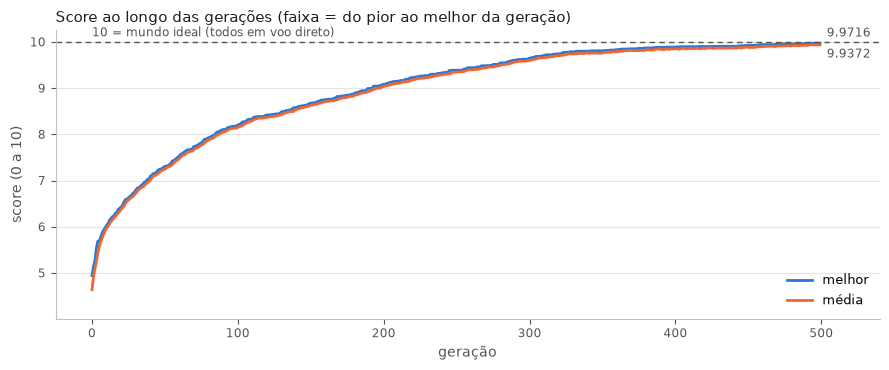

In [24]:
COR_1, COR_2 = "#2a78d6", "#eb6834"
TINTA, TINTA_2, GRADE = "#1f1f1d", "#55554f", "#e6e5e0"


def _estilo(ax, titulo=None):
    if titulo:
        ax.set_title(titulo, loc="left", fontsize=10.5, color=TINTA)
    ax.grid(axis="y", color=GRADE, linewidth=0.8)
    ax.set_axisbelow(True)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    for lado in ("left", "bottom"):
        ax.spines[lado].set_color("#c3c2b7")
    ax.tick_params(colors=TINTA_2, labelsize=8.5)


fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(h.index, h["fitness melhor"], color=COR_1, linewidth=2, label="melhor")
ax.plot(h.index, h["fitness média"], color=COR_2, linewidth=2, label="média")
ax.fill_between(h.index, h["fitness pior"], h["fitness melhor"], color=COR_1, alpha=0.08, linewidth=0)
for col, dy in (("fitness melhor", 7), ("fitness média", -7)):
    ax.annotate(f"{h[col].iloc[-1]:.4f}", (h.index[-1], h[col].iloc[-1]), xytext=(5, dy),
                textcoords="offset points", va="center", fontsize=8.5, color=TINTA_2)
ax.axhline(10, color=TINTA_2, linewidth=1, linestyle=(0, (4, 3)))
ax.annotate("10 = mundo ideal (todos em voo direto)", (0, 10), xytext=(0, 4), textcoords="offset points",
            fontsize=8.5, color=TINTA_2)
ax.set_xlim(right=h.index[-1] * 1.08 + 1)
ax.set_ylim(top=10.25)
ax.set_xlabel("geração", color=TINTA_2)
ax.set_ylabel("score (0 a 10)", color=TINTA_2)
ax.legend(frameon=False, fontsize=9, loc="lower right")
_estilo(ax, "Score ao longo das gerações (faixa = do pior ao melhor da geração)")
fig.tight_layout()
plt.show()

**Evolução dos números pedidos no enunciado** (sempre do melhor indivíduo de cada geração).
Um gráfico por grandeza, cada um com sua própria escala. Como ler:

- O **tempo total de voo dos passageiros sobe**. Isso é bom: é consequência de mais gente viajando.
  O que mede a eficiência é o **tempo médio**, que cai.
- O **número de voos** e a **ocupação** sobem juntos: o AG não só cria voos, mas os coloca onde há demanda.
- As **aeronaves utilizadas** sobem de ~290 para quase 400. Na população inicial muitos aviões ficam
  parados, porque genes longos quase sempre são descartados na validação. A seleção natural descobre
  sozinha que pôr um avião para voar compensa: qualquer voo que leve passageiros remanescentes reduz o
  custo (hierarquia da Seção 3).

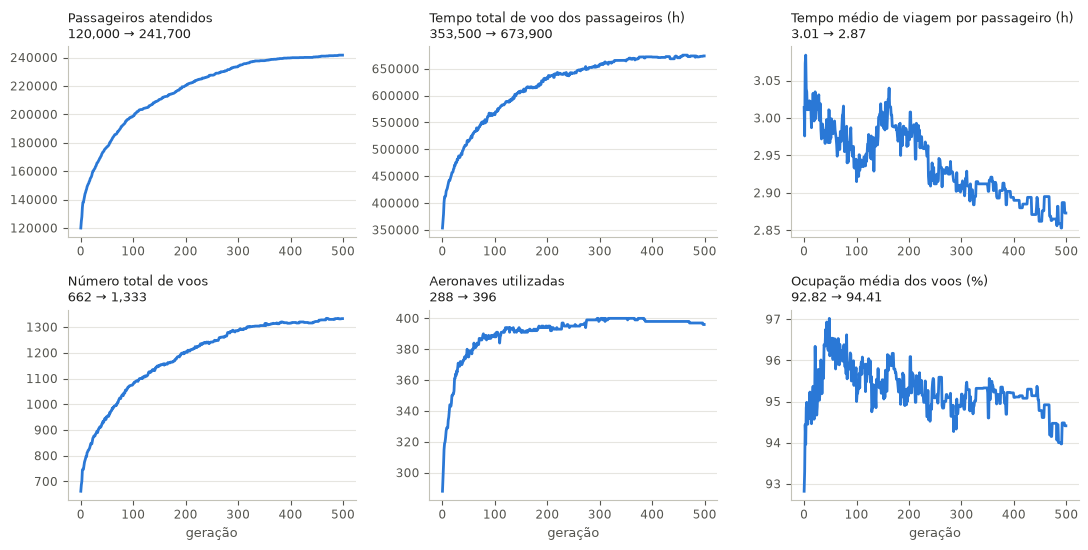

In [25]:
paineis = [("atendidos", "Passageiros atendidos"),
           ("tempo voo pax total (h)", "Tempo total de voo dos passageiros (h)"),
           ("tempo médio viagem (h)", "Tempo médio de viagem por passageiro (h)"),
           ("voos", "Número total de voos"),
           ("aeronaves usadas", "Aeronaves utilizadas"),
           ("ocupação média (%)", "Ocupação média dos voos (%)")]

fig, axs = plt.subplots(2, 3, figsize=(11, 5.6))
for ax, (col, titulo) in zip(axs.flat, paineis):
    ax.plot(h.index, h[col], color=COR_1, linewidth=2)
    ini, fim = h[col].iloc[0], h[col].iloc[-1]
    fmt = (lambda v: f"{v:,.0f}") if abs(fim) >= 100 else (lambda v: f"{v:.2f}")
    ax.set_title(f"{titulo}\n{fmt(ini)} → {fmt(fim)}", loc="left", fontsize=9.5, color=TINTA)
    ax.ticklabel_format(axis="y", style="plain", useOffset=False)
    _estilo(ax)
for ax in axs[1]:
    ax.set_xlabel("geração", color=TINTA_2, fontsize=9)
fig.tight_layout()
plt.show()

---
## 5. Resultados: o melhor plano encontrado

Último passo do pseudocódigo: `best = argmax(score)` e `mostra_tabela(AP_list[best])`. Por causa do
elitismo, o melhor da última geração é também o melhor de todas as gerações.

In [26]:
best = resultado.best
AP_best, AV_best, av_best = resultado.AP_list[best], resultado.AV_list[best], resultado.melhor

# validação completa do vencedor
assert validar_genoma(resultado.genomas[best]) == []
assert validar_plano(AV_best) == [] and validar_alocacao(AP_best) == []
print(f"Melhor plano: indivíduo {best} da geração {resultado.historico.index[-1]} — "
      f"score {av_best.fitness:.4f} de 10  |  física, plano e alocação validados ✓")

ini = resultado.historico.iloc[0]
_num = lambda xs: [int(x) if float(x).is_integer() else x for x in xs]
numeros = pd.DataFrame(dtype=object, data={
    "geração 0 (melhor aleatório)": _num([round(ini["fitness melhor"], 4), ini["atendidos"], ini["% atendimento"], ini["tempo voo pax total (h)"],
                                     ini["tempo viagem total (h)"], ini["tempo médio viagem (h)"],
                                     ini["voos"], ini["aeronaves usadas"], ini["ocupação média (%)"]]),
    "melhor plano final": _num([round(av_best.fitness, 4), av_best.atendidos, round(av_best.pct_atendimento, 2),
                           av_best.tempo_voo_pax_total_h, av_best.tempo_viagem_total_h,
                           round(av_best.tempo_medio_viagem_h, 3), av_best.n_voos,
                           av_best.aeronaves_usadas, round(100 * av_best.ocupacao_media, 2)]),
}, index=["score (0 a 10)", "passageiros atendidos", "% da demanda", "tempo total de voo dos passageiros (h)",
          "tempo total de viagem dos passageiros (h)", "tempo médio de viagem por passageiro (h)",
          "nº total de voos", "nº de aeronaves utilizadas", "ocupação média dos voos (%)"])
numeros.astype(object)

Melhor plano: indivíduo 0 da geração 499 — score 9.9716 de 10  |  física, plano e alocação validados ✓


,geração 0 (melhor aleatório),melhor plano final
score (0 a 10),4.9432,9.9716
passageiros atendidos,120000,241700
% da demanda,49.59,99.88
tempo total de voo dos passageiros (h),353500,673900
tempo total de viagem dos passageiros (h),361700,694500
tempo médio de viagem por passageiro (h),3.014,2.873
nº total de voos,662,1333
nº de aeronaves utilizadas,288,396
ocupação média dos voos (%),92.82,94.41


In [27]:
mostra_tabela(AP_best)
print("Passageiros por tipo de rota:")
resumo_alocacao(AP_best)

TAB_AP — 241,700 atendidos, 300 remanescentes (primeiros 10 grupos):


,n,origem,destino,voos,escalas,partida,chegada,tempo_viagem_h
passageiros,,,,,,,,
P000001–P000200,200,MA,BE,V0662,0,06:00,08:00,2
P000201–P000400,200,MA,BE,V0916,0,06:00,08:00,2
P000401–P000600,200,MA,BE,V0864,0,13:00,15:00,2
P000601–P000800,200,MA,BE,V0411,0,14:00,16:00,2
P000801–P001000,200,MA,FO,V0127,0,06:00,09:00,3
P001001–P001200,200,MA,FO,V0124,0,07:00,10:00,3
P001201–P001400,200,MA,FO,V0479,0,11:00,14:00,3
P001401–P001600,200,MA,FO,V0118,0,20:00,23:00,3
P001601–P001700,100,MA,FO,V0271,0,20:00,23:00,3


TAB_AP por passageiro (formato do PDF), amostra:
  P000001: [ (MA)(BE) ] [ V0662 ]
  P030251: [ (FO)(SA) ] [ V0844 ]
  P060501: [ (RE)(RJ) ] [ V0187 ]
  P090751: [ (BR)(NA) ] [ V0603 ]
  P121001: [ (BH)(CI) ] [ V0357 ]
  P151251: [ (RJ)(BH) ] [ V1049 ]
  P181501: [ (SP)(BR) ] [ V1187 ]
  P211751: [ (CR)(RJ) ] [ V0857 ]

TAB_AV — 1,333 voos (primeiros 10):


,aeronave,origem,destino,partida,chegada,duracao_min,n_passag
voo,,,,,,,
V0001,A001,FO,SP,07:00,11:00,240,200
V0002,A001,SP,CR,12:00,13:00,60,200
V0003,A001,CR,BH,15:00,17:00,120,0
V0004,A001,BH,SP,19:00,20:00,60,200
V0005,A001,SP,RE,21:00,00:00(+1d),180,200
V0006,A002,BH,SA,08:00,10:00,120,200
V0007,A002,SA,SP,11:00,13:00,120,200
V0008,A002,SP,BR,14:00,16:00,120,200
V0009,A003,BE,BH,08:00,12:00,240,200


TAB_PV — por aeronave (primeiras 10):


,base,n_voos,horas_voo,termina_em,sequencia
aeronave,,,,,
A001,FO,5,11,RE,V0001 FO-SP 07h → V0002 SP-CR 12h → V0003 CR-B...
A002,BH,3,6,BR,V0006 BH-SA 08h → V0007 SA-SP 11h → V0008 SP-B...
A003,BE,2,7,FO,V0009 BE-BH 08h → V0010 BH-FO 13h
A004,BR,4,6,RE,V0011 BR-BH 06h → V0012 BH-SP 08h → V0013 SP-S...
A005,BH,5,14,FO,V0015 BH-SP 07h → V0016 SP-RJ 10h → V0017 RJ-R...
A006,BE,3,9,FO,V0020 BE-RJ 06h → V0021 RJ-BR 11h → V0022 BR-F...
A007,FO,3,8,BR,V0023 FO-BE 08h → V0024 BE-SP 11h → V0025 SP-B...
A008,FL,4,14,MA,V0026 FL-SA 06h → V0027 SA-NA 12h → V0028 NA-S...
A009,RJ,4,8,RJ,V0030 RJ-SP 09h → V0031 SP-RE 13h → V0032 RE-S...


TAB_MV — nº de decolagens por aeroporto de origem e horário:


,06:00,07:00,08:00,09:00,10:00,11:00,12:00,13:00,14:00,15:00,16:00,17:00,18:00,19:00,20:00,21:00
origem,,,,,,,,,,,,,,,,
MA,19,6,5,3,2,3,2,5,4,4,2,3,1,1,5,7
BE,13,9,6,4,1,4,3,4,4,2,4,4,4,1,7,5
FO,9,7,3,3,2,5,4,6,6,5,8,6,2,4,4,2
NA,11,4,3,2,5,2,3,5,5,7,3,3,4,6,2,5
RE,16,5,2,3,6,6,5,5,4,7,6,4,7,6,3,5
SA,14,11,4,7,7,6,6,6,6,7,10,4,2,1,7,1
BR,20,4,5,8,21,10,5,9,8,8,7,9,10,6,7,8
BH,9,2,8,7,8,8,6,5,5,1,4,7,3,4,3,5
CI,10,4,2,1,4,6,3,2,4,4,3,4,2,2,3,1


Passageiros por tipo de rota:


,passageiros,% demanda,tempo médio (h)
tipo,,,
direto,232500,96.07,2.70
1 escala(s),8400,3.47,6.85
2 escala(s),800,0.33,12.50
remanescentes,300,0.12,NaN


**Ocupação e tempo de voo das aeronaves, e passageiros que conseguem viajar** — os três gráficos
pedidos pelo enunciado, para o melhor plano.

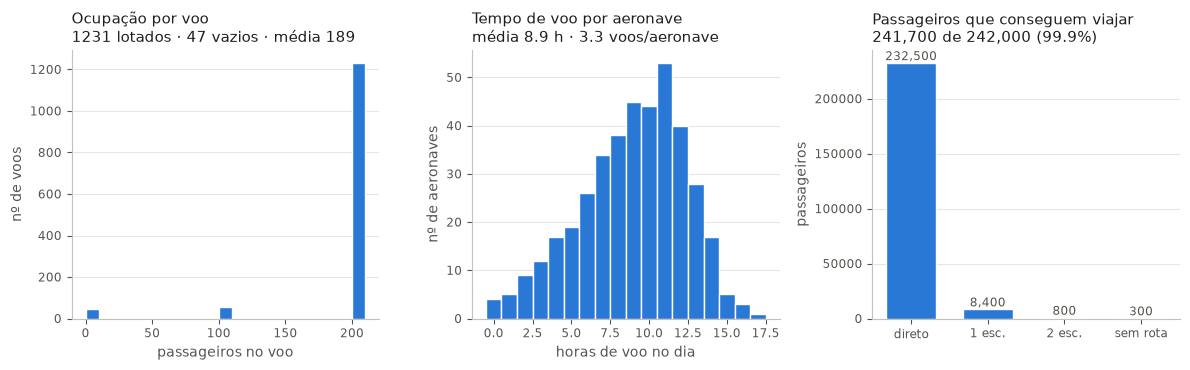

In [28]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3.8))

ocup = [v.total for v in AV_best.voos]
axs[0].hist(ocup, bins=range(0, CAPACIDADE + 11, 10), color=COR_1, edgecolor="white", linewidth=1)
axs[0].set_xlabel("passageiros no voo", color=TINTA_2)
axs[0].set_ylabel("nº de voos", color=TINTA_2)
_estilo(axs[0], f"Ocupação por voo\n{sum(o == CAPACIDADE for o in ocup)} lotados · "
                f"{sum(o == 0 for o in ocup)} vazios · média {np.mean(ocup):.0f}")

horas = [av.horas_voo for av in AV_best.aeronaves]
axs[1].hist(horas, bins=range(0, max(horas) + 2), color=COR_1, edgecolor="white", linewidth=1, align="left")
axs[1].set_xlabel("horas de voo no dia", color=TINTA_2)
axs[1].set_ylabel("nº de aeronaves", color=TINTA_2)
_estilo(axs[1], f"Tempo de voo por aeronave\nmédia {np.mean(horas):.1f} h · "
                f"{np.mean([len(av.voos) for av in AV_best.aeronaves]):.1f} voos/aeronave")

r = resumo_alocacao(AP_best)["passageiros"]
r.index = [t.replace("escala(s)", "esc.").replace("remanescentes", "sem rota") for t in r.index]
axs[2].bar(r.index, r.values, color=[COR_1] * (len(r) - 1) + ["#c3c2b7"], edgecolor="white", width=0.65)
for x, v in enumerate(r.values):
    axs[2].text(x, v, f"{v:,}", ha="center", va="bottom", fontsize=8.5, color=TINTA_2)
axs[2].set_ylabel("passageiros", color=TINTA_2)
_estilo(axs[2], f"Passageiros que conseguem viajar\n{av_best.atendidos:,} de {av_best.demanda:,} "
                f"({av_best.pct_atendimento:.1f}%)")
axs[2].ticklabel_format(axis="y", style="plain")

fig.tight_layout()
plt.show()

### Discussão

- **Ganho do AG.** A população inicial vem de genes sorteados livremente e filtrados pela validação:
  aviões com poucos voos e ~28% da frota parada, score ~4,9 e ~50% da demanda atendida. Em 500 gerações
  o AG chega a um score de **~9,97 de 10**, com **99,88% dos passageiros atendidos** (241 700 de 242 000),
  ~96% deles em voo direto, 1 333 voos, 396 aeronaves em uso e ocupação média de ~94%.
- **Seleção: torneio × truncamento.** A versão anterior usava torneio de 3; a atual usa truncamento
  (só os 10% melhores reproduzem, pai e mãe sorteados com reposição). Mesma semente, mesmos parâmetros:

  | Geração | Score — torneio de 3 | Score — truncamento 10% |
  |---|---|---|
  | 100 | 8,45 | 8,20 |
  | 200 | 9,32 | 9,08 |
  | 300 | 9,65 | 9,65 |
  | 400 | 9,88 | 9,89 |
  | 499 | 9,92 | **9,97** |
  | Atendidos no fim | 240 700 | **241 700** |
  | Voos no fim | 1 353 | **1 333** |

  O truncamento começa mais devagar e termina melhor: atende 1 000 passageiros a mais com 20 voos a menos.
  É uma única execução de cada (uma semente); para afirmar que um é melhor que o outro seria preciso
  repetir com várias sementes.
- **Genes livres × genes restritos.** Na versão com genes restritos (no máximo 8 trechos e espera de até
  3 h, impostos na construção), a população inicial começava em ~7,9 e o AG chegava a ~9,64 na geração 300.
  Com genes livres, o começo é bem pior (~4,9), mas na geração 300 o score já é o mesmo (~9,65): a mutação
  livre, com taxa maior, recupera o atraso.
- **Validação e descarte.** Só ~1 em cada 4 genes sorteados livremente é válido. Entre os filhos, com
  `TAXA_MUTACAO = 0,04`, ~97% saem inválidos e são descartados. Isso é barato (gerar e validar um filho
  custa ~1 ms, avaliar custa ~25 ms) e funciona como a seleção de embriões inviáveis.
- **Ainda subindo.** O score passa de ~9,89 (geração 400) para ~9,97 (geração 499) e ainda subia nas
  últimas gerações. O critério de convergência (ganho ≤ `LIMIAR` em `PACIENCIA` gerações) não disparou:
  mais gerações provavelmente melhorariam um pouco o resultado.
- **Ocupação "em degraus".** Quase todos os voos saem lotados (200) e os demais têm 100 ou 0 passageiros,
  porque toda a TAB_OD está em múltiplos de 100 e o alocador enche um voo antes de passar ao próximo.
- **Passageiros remanescentes.** Os 300 que sobram (0,12%) não encontram assento livre em nenhuma rota com
  até `MAX_ESCALAS` escalas: falta assento no lugar certo, e só o AG consegue criá-lo.